# L20 worked example: learning to act from rewards

Every model so far in the course was fitted to recorded data against a known answer. Here the
learner collects its own data by acting and is only told how well things went:

1. **A bandit.** Five candidate catalysts, 500 runs. Which strategy loses the least yield to not
   knowing the best one? No state: the next run does not depend on the last.
2. **Q-learning by hand.** A three-level tank whose Q-table is a 3 × 2 matrix, with every
   number in the first six updates printed.
3. **Q-learning on a tank.** The level the controller leaves behind is the level it faces next.
   The tank and the settings are from the PyCSE chapter on reinforcement learning. The agent is
   compared with a PID loop **tuned here**, over **ten seeds** and **eight starting levels**.
4. **Two rewards that miss the point.** The same agent, told to "keep it steady" or to stay
   "inside 5 ± 1".
5. **Cliff walking.** Q-learning and SARSA learn different paths, and the difference is about
   exploring.
6. **A continuous valve.** A Gaussian policy trained by REINFORCE outputs the inflow directly.

NumPy only. The whole notebook runs in about three minutes on a laptop.

## Run this first on Colab

Colab starts from its own preinstalled environment rather than this course's `uv`
environment, so run the cell below before anything else. It installs what this
notebook needs and Colab does not already have. Outside Colab it does nothing, so
you can run it or skip it.


In [ ]:
# Run this first on Colab. Anywhere else this cell does nothing.
#
# Only genuinely missing packages are installed, so Colab's own versions of
# everything it already ships are left alone.
import importlib.util
import subprocess
import sys

REQUIREMENTS = {
    "gymnasium": "gymnasium",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "stable_baselines3": "stable_baselines3",
}


def _missing(module):
    try:
        return importlib.util.find_spec(module) is None
    except ModuleNotFoundError:  # the parent package is absent
        return True


if "google.colab" in sys.modules:
    need = sorted({pip for mod, pip in REQUIREMENTS.items() if _missing(mod)})
    if need:
        print("installing:", " ".join(need))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
    print("Colab setup done." if need else "Colab: nothing to install.")


In [2]:
import numpy as np
import matplotlib.pyplot as plt

## 1. A bandit: five catalysts

Each run of catalyst $a$ gives a yield drawn from a normal distribution with mean $\mu_a$ and
standard deviation 8 points. The learner does not know the means. **Regret** after $T$ runs is
$\sum_t (\mu^* - \mu_{a_t})$, the yield given up by not always using the best catalyst.

Four strategies. *Greedy* uses the best average so far. *ε-greedy* does the same but picks at
random one time in ten. *UCB* adds a bonus $c\sqrt{\ln t / n_a}$ that shrinks as an arm is
tried, the acquisition function of Lecture 15 without the Gaussian process. *Thompson sampling*
draws one plausible mean per arm from a Gaussian posterior and picks the largest.

In [3]:
MEANS = np.array([62.0, 70.0, 74.0, 66.0, 58.0])   # catalysts A to E, mean yield %
SD = 8.0                                           # run-to-run spread of one measurement


def bandit_run(method, rng, T=500, eps=0.1, c=SD, prior=(65.0, 15.0)):
    k = len(MEANS)
    n, q = np.zeros(k), np.zeros(k)
    regret, picks = np.zeros(T), np.zeros(T, int)
    for t in range(T):
        if method == "greedy":
            a = int(np.argmax(q)) if t >= k else t
        elif method == "eps":
            a = int(rng.integers(k)) if rng.random() < eps else int(np.argmax(q))
        elif method == "ucb":
            a = t if t < k else int(np.argmax(q + c * np.sqrt(np.log(t + 1) / n)))
        elif method == "thompson":
            m0, s0 = prior
            prec = 1 / s0**2 + n / SD**2
            mean = (m0 / s0**2 + q * n / SD**2) / prec
            a = int(np.argmax(rng.normal(mean, 1 / np.sqrt(prec))))
        r = rng.normal(MEANS[a], SD)
        n[a] += 1
        q[a] += (r - q[a]) / n[a]          # running average of this arm's yields
        regret[t] = MEANS.max() - MEANS[a]
        picks[t] = a
    return np.cumsum(regret), picks


runs = 500
for label, method, c in [("greedy", "greedy", SD), ("eps-greedy 0.1", "eps", SD),
                         ("UCB, c = 2", "ucb", 2.0), ("UCB, c = 8", "ucb", SD),
                         ("Thompson", "thompson", SD)]:
    rng = np.random.default_rng(20)
    final, best = [], []
    for _ in range(runs):
        cum, picks = bandit_run(method, rng, c=c)
        final.append(cum[-1])
        best.append(np.mean(picks[-100:] == 2))
    best = np.array(best)
    print(f"{label:15s} regret {np.mean(final):6.1f}   last 100 on Cat C {best.mean():.2f}   "
          f"stuck on a wrong arm {np.mean(best < 0.5):.1%}")

greedy          regret  663.7   last 100 on Cat C 0.73   stuck on a wrong arm 26.6%


eps-greedy 0.1  regret  883.9   last 100 on Cat C 0.90   stuck on a wrong arm 2.2%


UCB, c = 2      regret  422.6   last 100 on Cat C 0.84   stuck on a wrong arm 16.2%


UCB, c = 8      regret  211.4   last 100 on Cat C 0.98   stuck on a wrong arm 0.6%


Thompson        regret  269.3   last 100 on Cat C 0.98   stuck on a wrong arm 0.0%


Greedy gets stuck in about a quarter of the runs: one unlucky early yield from catalyst C and
it never tries C again. ε-greedy never gets stuck but keeps paying for random pulls forever.
UCB's constant has the **units of the reward**: $c = 2$ is the value in Sutton & Barto's
examples, whose rewards have a spread of about 1, and here it under-explores. Lecture 15 wrote
UCB as $\mu + \kappa\sigma$ for the same reason.

## 2. Q-learning by hand

A tank small enough to update on paper: three levels (low, ok, high) and two actions. **Open**
raises the level one step and **shut** lowers it one step. Landing at ok earns +1 and opening
costs 0.1. The Q-table is a 3 × 2 matrix of zeros; α = 0.5, γ = 0.9. The first six updates
follow a scripted episode so you can check every number against the notes.

In [4]:
LEVELS, ACTS = ["low", "ok", "high"], ["shut", "open"]

def small_step(s, a):
    s2 = min(s + 1, 2) if a == 1 else max(s - 1, 0)
    return s2, (1.0 if s2 == 1 else 0.0) - 0.1 * a

Qh, al, g = np.zeros((3, 2)), 0.5, 0.9

def update(s, a, show=False):
    s2, r = small_step(s, a)
    target = r + g * Qh[s2].max()
    td = target - Qh[s, a]
    if show:
        print(f"{LEVELS[s]:>4} -> {ACTS[a]:4} -> {LEVELS[s2]:4}  r = {r:4.1f}  "
              f"target = {r:4.1f} + {g} x {Qh[s2].max():.3f} = {target:6.3f}  "
              f"TD = {td:6.3f}  Q: {Qh[s, a]:6.3f} -> {Qh[s, a] + al * td:6.3f}")
    Qh[s, a] += al * td
    return s2

for s, a in [(0, 1), (1, 1), (2, 0), (1, 0), (0, 1), (1, 1)]:
    update(s, a, show=True)
print(np.round(Qh, 3))

 low -> open -> ok    r =  0.9  target =  0.9 + 0.9 x 0.000 =  0.900  TD =  0.900  Q:  0.000 ->  0.450
  ok -> open -> high  r = -0.1  target = -0.1 + 0.9 x 0.000 = -0.100  TD = -0.100  Q:  0.000 -> -0.050
high -> shut -> ok    r =  1.0  target =  1.0 + 0.9 x 0.000 =  1.000  TD =  1.000  Q:  0.000 ->  0.500
  ok -> shut -> low   r =  0.0  target =  0.0 + 0.9 x 0.450 =  0.405  TD =  0.405  Q:  0.000 ->  0.203
 low -> open -> ok    r =  0.9  target =  0.9 + 0.9 x 0.203 =  1.082  TD =  0.632  Q:  0.450 ->  0.766
  ok -> open -> high  r = -0.1  target = -0.1 + 0.9 x 0.500 =  0.350  TD =  0.400  Q: -0.050 ->  0.150
[[0.    0.766]
 [0.202 0.15 ]
 [0.5   0.   ]]


Now 300 ε-greedy steps, and the answer from the Bellman equation by value iteration for
comparison. The greedy policy is the argmax of each row.

In [5]:
rng = np.random.default_rng(3)
s = 0
for t in range(300):
    if t % 10 == 0:
        s = int(rng.integers(3))
    a = int(rng.integers(2)) if rng.random() < 0.3 else int(np.argmax(Qh[s]))
    s = update(s, a)

Qstar = np.zeros((3, 2))
for _ in range(2000):
    Qstar = np.array([[small_step(s, a)[1] + g * Qstar[small_step(s, a)[0]].max() for a in range(2)] for s in range(3)])
print("Q after 306 updates\n", np.round(Qh, 3))
print("Q* from value iteration\n", np.round(Qstar, 3))
print("greedy action in each row:", {LEVELS[i]: ACTS[int(np.argmax(Qh[i]))] for i in range(3)})

Q after 306 updates
 [[4.261 4.735]
 [4.261 4.238]
 [4.831 2.479]]
Q* from value iteration
 [[4.263 4.737]
 [4.263 4.253]
 [4.837 4.253]]
greedy action in each row: {'low': 'open', 'ok': 'shut', 'high': 'shut'}


## 3. Q-learning on a tank

The PyCSE tank: $dh/dt = (F - k\sqrt{h})/A$ with $A = 1$, $k = 0.5$, setpoint 5, Euler steps of
0.5, inflow $F$ chosen from five values. The level is cut into 20 bins, which are the states.
The reward is $-(h-5)^2 - 0.01F^2$. Episodes start at a random level in $[1, 9]$ and last 100
steps.

In [6]:
FLOWS = [0.0, 0.5, 1.0, 1.5, 2.0]
A, K, SETPOINT, DT, STEPS, NBINS = 1.0, 0.5, 5.0, 0.5, 100, 20


def tank_bin(h):
    return min(int(min(max(h, 0.0), 10.0) / 10.0 * (NBINS - 1)), NBINS - 1)


def tank_step(h, F):
    return max(0.0, h + DT * (F - K * np.sqrt(max(h, 0.0))) / A)


def reward_fn(kind, h, h_prev, F):
    if kind == "setpoint":
        return -(h - SETPOINT) ** 2 - 0.01 * F**2
    if kind == "steady":
        return -abs(h - h_prev)
    if kind == "band":
        return 1.0 if abs(h - SETPOINT) <= 1.0 else 0.0


def q_learning(seed, episodes=1000, alpha=0.2, gamma=0.95, eps=0.2, reward="setpoint", flows=FLOWS):
    rng = np.random.default_rng(seed)
    Q = np.zeros((NBINS, len(flows)))
    totals = []
    for _ in range(episodes):
        h = rng.uniform(1.0, 9.0)
        s, total = tank_bin(h), 0.0
        for _ in range(STEPS):
            a = int(rng.integers(len(flows))) if rng.random() < eps else int(np.argmax(Q[s]))
            h2 = tank_step(h, flows[a])
            r = reward_fn(reward, h2, h, flows[a])
            s2 = tank_bin(h2)
            # The Q-learning update: toward r plus the discounted best value of the next state
            Q[s, a] += alpha * (r + gamma * Q[s2].max() - Q[s, a])
            s, h, total = s2, h2, total + r
        totals.append(total)
    return Q, np.array(totals)


Q0, totals = q_learning(0)
print("Q-table shape:", Q0.shape, "  transitions used:", 1000 * STEPS)
print(f"total reward per episode: first 50 {totals[:50].mean():.1f}, last 50 {totals[-50:].mean():.1f}")
print("greedy inflow by level bin:", [FLOWS[int(np.argmax(Q0[b]))] for b in range(NBINS)])

Q-table shape: (20, 5)   transitions used: 100000
total reward per episode: first 50 -33.8, last 50 -13.7
greedy inflow by level bin: [0.0, 1.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 1.0, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, 0.5, 0.0]


Now the comparison. PyCSE compares the agent with a PID loop using hand-picked gains
$(K_p, K_i, K_d) = (0.8, 0.1, 0.2)$ from one start, $h = 2$. A fair comparison tunes the PID
loop, tests from several starts, and trains the agent with several seeds.

In [7]:
def run_policy(Q, h0, flows=FLOWS):
    h, hs, fs = h0, [h0], []
    for _ in range(STEPS):
        F = flows[int(np.argmax(Q[tank_bin(h)]))]
        h = tank_step(h, F)
        hs.append(h)
        fs.append(F)
    return np.array(hs), np.array(fs)


def run_pid(Kp, Ki, Kd, h0, quantize=False):
    h, integ, prev = h0, 0.0, SETPOINT - h0
    hs, fs = [h0], []
    for _ in range(STEPS):
        e = SETPOINT - h
        integ += e * DT
        F = float(np.clip(Kp * e + Ki * integ + Kd * (e - prev) / DT, 0.0, 2.0))
        prev = e
        if quantize:                       # force the PID onto the agent's five inflows
            F = min(FLOWS, key=lambda f: abs(f - F))
        h = tank_step(h, F)
        hs.append(h)
        fs.append(F)
    return np.array(hs), np.array(fs)


def mse(hs):
    return float(np.mean((hs - SETPOINT) ** 2))


STARTS = [1.0, 2.0, 3.0, 4.0, 6.0, 7.0, 8.0, 9.0]

# Tune the PID on the eight starts with a plain grid search
best = min(((np.mean([mse(run_pid(kp, ki, kd, h0)[0]) for h0 in STARTS]), round(float(kp), 2), ki, kd)
            for kp in np.arange(0.2, 4.01, 0.2) for ki in [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
            for kd in [0.0, 0.1, 0.2]))
TUNED = best[1:]
print("tuned PID gains (Kp, Ki, Kd):", TUNED)

Qs = [q_learning(s)[0] for s in range(10)]
per_seed = [float(np.mean([mse(run_policy(Q, h0)[0]) for h0 in STARTS])) for Q in Qs]

print(f"\nfrom h = 2 only:   agent {np.mean([mse(run_policy(Q, 2.0)[0]) for Q in Qs]):.3f} (10 seeds)   "
      f"PyCSE PID {mse(run_pid(0.8, 0.1, 0.2, 2.0)[0]):.3f}   tuned PID {mse(run_pid(*TUNED, 2.0)[0]):.3f}")
print(f"over eight starts: agent {np.mean(per_seed):.3f} +/- {np.std(per_seed):.3f}   "
      f"PyCSE PID {np.mean([mse(run_pid(0.8, 0.1, 0.2, h0)[0]) for h0 in STARTS]):.3f}   "
      f"tuned PID {best[0]:.3f}   tuned PID on five inflows "
      f"{np.mean([mse(run_pid(*TUNED, h0, quantize=True)[0]) for h0 in STARTS]):.3f}")
print("agent, each seed over eight starts:", [round(v, 2) for v in per_seed])

tuned PID gains (Kp, Ki, Kd): (3.6, 0.3, 0.0)



from h = 2 only:   agent 0.221 (10 seeds)   PyCSE PID 0.268   tuned PID 0.196
over eight starts: agent 1.400 +/- 1.313   PyCSE PID 0.323   tuned PID 0.189   tuned PID on five inflows 0.222
agent, each seed over eight starts: [2.48, 0.19, 4.08, 2.15, 2.14, 0.21, 0.2, 0.21, 2.14, 0.19]


From $h = 2$ the agent beats the untuned PID, which is PyCSE's result. Over eight starts and ten
seeds the picture splits: about half the seeds learn a policy as good as the tuned PID, and the
rest fail badly from at least one start that training rarely visited.

The action set is the other problem. At steady state $F = k\sqrt{h}$, so each of the five
inflows holds one level, and none of them is 5.

steady level for each inflow, h = (F/k)^2: [0.0, 1.0, 4.0, 9.0, 16.0]
inflow that would hold h = 5: 1.118
agent's inflows in the last 40 steps: {1.0: 35, 2.0: 5}   switches: 10


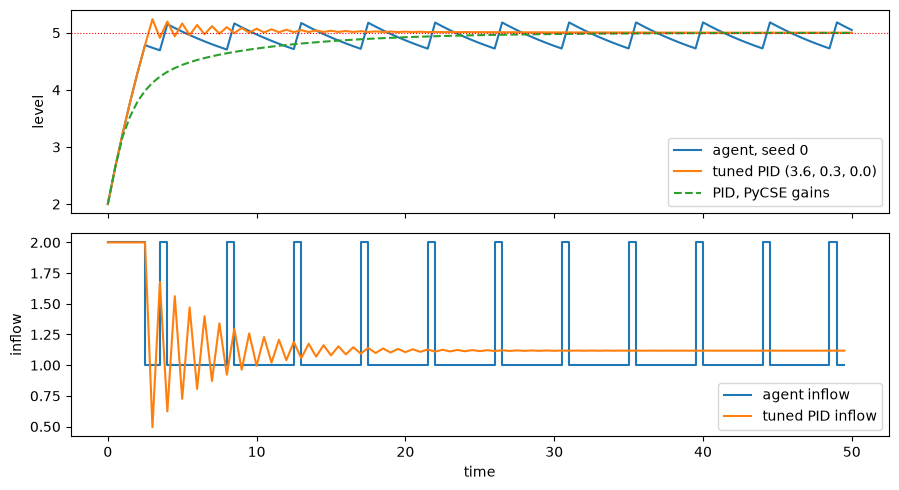

In [8]:
print("steady level for each inflow, h = (F/k)^2:", [(F / K) ** 2 for F in FLOWS])
print("inflow that would hold h = 5:", round(K * np.sqrt(5), 3))

hs, fs = run_policy(Qs[0], 2.0)
tail = fs[-40:]
print("agent's inflows in the last 40 steps:", {float(f): int(np.sum(tail == f)) for f in sorted(set(tail))},
      "  switches:", int(np.sum(tail[1:] != tail[:-1])))

t = np.arange(STEPS + 1) * DT
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(t, hs, label="agent, seed 0")
ax[0].plot(t, run_pid(*TUNED, 2.0)[0], label=f"tuned PID {TUNED}")
ax[0].plot(t, run_pid(0.8, 0.1, 0.2, 2.0)[0], "--", label="PID, PyCSE gains")
ax[0].axhline(SETPOINT, color="r", lw=0.8, ls=":")
ax[0].set_ylabel("level")
ax[0].legend()
ax[1].step(t[:-1], fs, where="post", label="agent inflow")
ax[1].plot(t[:-1], run_pid(*TUNED, 2.0)[1], label="tuned PID inflow")
ax[1].set_ylabel("inflow")
ax[1].set_xlabel("time")
ax[1].legend()
plt.tight_layout()
plt.show()

## 4. Two rewards that miss the point

The reward is the only description of the goal the agent sees. "Keep the level steady" becomes
$-|h_{t+1} - h_t|$; "stay near 5" becomes $+1$ inside $5 \pm 1$. Same agent, same tank.

In [9]:
for kind in ["steady", "band"]:
    Q = q_learning(0, reward=kind)[0]
    finals = [round(float(run_policy(Q, h0)[0][-1]), 2) for h0 in STARTS]
    print(f"{kind:7s} final level from each start {STARTS}: {finals}")

steady  final level from each start [1.0, 2.0, 3.0, 4.0, 6.0, 7.0, 8.0, 9.0]: [1.0, 1.0, 4.0, 4.0, 4.0, 8.97, 8.99, 9.0]


band    final level from each start [1.0, 2.0, 3.0, 4.0, 6.0, 7.0, 8.0, 9.0]: [4.27, 4.42, 4.22, 4.58, 4.35, 4.22, 4.39, 4.2]


Under "steady" the agent parks the tank at the nearest level one inflow can hold, 1, 4 or 9,
and leaves it there: perfectly steady, and the setpoint was never in the reward. Under "band" it
hovers in the lower half of the band, because nothing says 5 is better than 4.3. This is
**specification gaming**.

## 5. Cliff walking: Q-learning against SARSA

A 4 × 12 grid. Start bottom left, goal bottom right, −1 per step, and the cells between them on
the bottom row are a cliff: −100 and back to the start. SARSA updates toward the action it will
actually take next; Q-learning toward the best one.

In [10]:
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]   # up, right, down, left
START, GOAL = (3, 0), (3, 11)


def cliff_step(pos, a):
    r, c = pos
    r = min(max(r + MOVES[a][0], 0), 3)
    c = min(max(c + MOVES[a][1], 0), 11)
    if r == 3 and 0 < c < 11:
        return START, -100, False
    return (r, c), -1, (r, c) == GOAL


def cliff_learn(method, seed, episodes=500, alpha=0.5, eps=0.1):
    rng = np.random.default_rng(seed)
    Q = np.zeros((4, 12, 4))

    def pick(p):
        if rng.random() < eps:
            return int(rng.integers(4))
        return int(rng.choice(np.flatnonzero(Q[p] == Q[p].max())))

    returns = []
    for _ in range(episodes):
        p, G, done, steps = START, 0, False, 0
        a = pick(p)
        while not done and steps < 1000:
            p2, r, done = cliff_step(p, a)
            a2 = pick(p2)
            nxt = Q[p2].max() if method == "q" else Q[p2][a2]
            Q[p][a] += alpha * ((r if done else r + nxt) - Q[p][a])
            p, a, G, steps = p2, a2, G + r, steps + 1
        returns.append(G)
    return Q, np.array(returns)


def greedy_path(Q):
    p, path = START, [START]
    for _ in range(60):
        p, r, done = cliff_step(p, int(np.argmax(Q[p])))
        path.append(p)
        if done or r == -100:
            break
    return path


for method, name in [("sarsa", "SARSA"), ("q", "Q-learning")]:
    results = [cliff_learn(method, s) for s in range(50)]
    online = np.mean([ret[-100:].mean() for _, ret in results])
    lengths = [len(greedy_path(Q)) - 1 for Q, _ in results]
    print(f"{name:10s} return while learning (last 100 episodes): {online:6.1f}   "
          f"greedy path length, most common: {np.bincount(lengths).argmax()}")

SARSA      return while learning (last 100 episodes):  -26.4   greedy path length, most common: 17


Q-learning return while learning (last 100 episodes):  -49.3   greedy path length, most common: 13


Q-learning learns the shortest path, along the edge, and falls off during learning whenever an
exploratory move points down. SARSA learns the value of what it actually does, random moves
included, and keeps its distance. On a plant, exploration happens on the equipment, which is why
real controllers are trained in simulators.

## 6. A continuous valve: a policy that outputs the inflow

A Q-table picks an action by argmax over its columns, which needs actions you can list. A
**Gaussian policy** outputs the action instead: a mean $\mu = \theta_0 + \theta_1 (5 - h)$ and a
fixed spread σ = 0.3, from which the inflow is sampled and clipped to $[0, 2]$. **REINFORCE**
(Williams, 1992) makes the inflows that were followed by better-than-average returns more likely.
Three seeds here; the notes report ten. The inflow that holds $h = 5$ is $k\sqrt{5} = 1.118$.

In [11]:
def pg_train(seed, iters=300, batch=10, lr=0.01, sigma=0.3, gamma=0.95):
    rng = np.random.default_rng(seed)
    theta = np.zeros(2)
    for _ in range(iters):
        eps = []
        for _ in range(batch):
            h, xs, Fs, rs = rng.uniform(1.0, 9.0), [], [], []
            for _ in range(STEPS):
                x = np.array([1.0, SETPOINT - h])
                F = float(theta @ x + sigma * rng.standard_normal())   # sample an action
                Fa = float(np.clip(F, 0.0, 2.0))
                h = tank_step(h, Fa)
                xs.append(x); Fs.append(F); rs.append(reward_fn("setpoint", h, None, Fa))
            G, acc = np.zeros(STEPS), 0.0
            for t in range(STEPS - 1, -1, -1):
                acc = rs[t] + gamma * acc
                G[t] = acc
            eps.append((np.array(xs), np.array(Fs), G))
        allG = np.concatenate([e[2] for e in eps])
        b, sd = allG.mean(), allG.std() + 1e-8
        grad = sum(((Fs - xs @ theta) / sigma**2 * (G - b) / sd) @ xs for xs, Fs, G in eps)
        theta = theta + lr * grad / batch
    return theta

def pg_run(theta, h0):
    h, hs = h0, [h0]
    for _ in range(STEPS):
        h = tank_step(h, float(np.clip(theta @ [1.0, SETPOINT - h], 0.0, 2.0)))   # the mean action
        hs.append(h)
    return np.array(hs)

for seed in range(3):
    th = pg_train(seed)
    print(f"seed {seed}: theta = {np.round(th, 3)},  MSE over eight starts "
          f"{np.mean([mse(pg_run(th, h0)) for h0 in STARTS]):.3f}   (tuned PID {best[0]:.3f})")

seed 0: theta = [ 1.185 10.451],  MSE over eight starts 0.227   (tuned PID 0.189)


seed 1: theta = [1.109 1.144],  MSE over eight starts 0.163   (tuned PID 0.189)


seed 2: theta = [1.125 1.56 ],  MSE over eight starts 0.163   (tuned PID 0.189)


The learned $\theta_0$ sits near the holding inflow 1.118, found from reward alone. The policy is
a proportional controller with a feedforward term, so the engineering went into choosing its
form; the reward tuned two numbers, using 300,000 transitions.

## 7. Optional: the same tank with Gymnasium and PPO

Gymnasium defines the environment interface (`reset`, `step`); Stable-Baselines3 provides PPO,
DQN, SAC and others. This cell runs only if both are installed
(`pip install gymnasium stable-baselines3`); the inflow is continuous in $[0, 2]$, which removes
the five-valve limit. Whether it beats the tuned PID is a question for the same three checks:
tuned baseline, several starts, several seeds.

In [12]:
try:
    import gymnasium as gym
    from gymnasium import spaces
    from stable_baselines3 import PPO
except ImportError:
    print("gymnasium or stable-baselines3 not installed: skipping this section")
else:
    class TankEnv(gym.Env):
        def __init__(self):
            self.action_space = spaces.Box(0.0, 2.0, shape=(1,), dtype=np.float32)
            self.observation_space = spaces.Box(0.0, 10.0, shape=(1,), dtype=np.float32)

        def reset(self, seed=None, options=None):
            super().reset(seed=seed)
            self.h, self.t = self.np_random.uniform(1.0, 9.0), 0
            return np.array([self.h], dtype=np.float32), {}

        def step(self, action):
            F = float(np.clip(action[0], 0.0, 2.0))
            self.h, self.t = min(tank_step(self.h, F), 10.0), self.t + 1
            reward = -(self.h - SETPOINT) ** 2 - 0.01 * F**2
            # a time limit is a truncation, not a real end: the future still has value
            return np.array([self.h], dtype=np.float32), reward, False, self.t >= STEPS, {}

    model = PPO("MlpPolicy", TankEnv(), seed=0, verbose=0).learn(total_timesteps=50_000)
    def ppo_mse(h0):
        env = TankEnv(); env.reset(seed=0); env.h = h0
        hs, obs = [h0], np.array([h0], dtype=np.float32)
        for _ in range(STEPS):
            obs, *_ = env.step(model.predict(obs, deterministic=True)[0])
            hs.append(float(obs[0]))
        return mse(np.array(hs))
    print(f"PPO, one seed, 50,000 steps: MSE over eight starts {np.mean([ppo_mse(h) for h in STARTS]):.3f}"
          f"   (tuned PID {best[0]:.3f})")

gymnasium or stable-baselines3 not installed: skipping this section


## Try it

- Train the tank agent for 5,000 episodes instead of 1,000. Do the failing seeds recover? Which
  starting levels were they failing from, and why would training rarely visit them?
- Add 1.125 to `FLOWS` (it holds $h = 5.06$). How do the switching count and the error change?
- Change γ from 0.95 to 0.5. What does the agent do near the setpoint, and why?
- Write a reward of your own for "reach 5 quickly and then hold it" and check what the agent
  actually does from every start.
- In the bandit, set UCB's `c` to 2, 8 and 30. Plot the regret curves. Where is the exploration
  constant too small, and where too large?
- Run cliff walking with ε = 0.01. Do the two paths still differ? What does that say about when
  SARSA's caution is worth having?